# Recursive Feature Elimination for Classification

## Objective

Can recursive feature elimination reduce the number of input features while maintaining classification performance? We compare Logistic Regression trained with all features against the same classifier trained with features selected by Feature-engine's `RecursiveFeatureElimination`. The primary metric is test ROC-AUC.

## Method and dataset

Recursive feature elimination (RFE) repeatedly fits an estimator, ranks the input features, removes a low-importance feature, and measures how the model performs with the reduced set. Feature-engine's `RecursiveFeatureElimination` uses cross-validation to evaluate each removal and keeps features when removal causes a performance decline larger than the chosen threshold.

This example uses scikit-learn's Breast Cancer Wisconsin dataset, which contains 569 observations and 30 numerical measurements. The binary target indicates whether a tumor is malignant or benign.

## Split and leakage prevention

We split the data into stratified training and test sets before fitting any selector. RFE is fitted using only `X_train` and `y_train`; the test set is reserved for the final model comparison. This matters because selecting features based on test-set labels would let information from the evaluation data influence the model and make its reported performance overly optimistic.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from feature_engine.selection import RecursiveFeatureElimination

# Load the dataset and create the holdout split before any feature selection.
X, y = load_breast_cancer(as_frame=True, return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

original_feature_count = X_train.shape[1]
print(f"Training samples: {X_train.shape[0]}")
print(f"Original features: {original_feature_count}")

Training samples: 455
Original features: 30


## Baseline model and scaling

Logistic Regression is sensitive to feature scale: measurements with larger numeric ranges can have disproportionate influence on its regularized coefficient estimates and optimization. We use a scikit-learn `Pipeline` with `StandardScaler` followed by `LogisticRegression`. During RFE's cross-validation, each fold fits its own scaler using only that fold's training rows; the final baseline model is likewise fitted only on the training split.

In [2]:
def make_logistic_model():
    return Pipeline(
        [
            ("scaler", StandardScaler()),
            (
                "classifier",
                LogisticRegression(max_iter=5000, random_state=42),
            ),
        ]
    )


baseline_model = make_logistic_model()
baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## Fit Feature-engine RFE

The selector evaluates models with three-fold cross-validation on the training split. The threshold is `0.001`: a feature can be removed when doing so lowers mean cross-validation ROC-AUC by no more than 0.001. The scaled Logistic Regression pipeline is passed as the estimator, so scaling is refitted inside each fold. Since the pipeline does not expose Logistic Regression's `coef_` directly, Feature-engine uses permutation importance to rank its input features. Neither RFE nor its importance calculations receive the held-out test set.

In [3]:
selector = RecursiveFeatureElimination(
    estimator=make_logistic_model(),
    scoring="roc_auc",
    cv=3,
    threshold=0.001,
)

# Learn the selected feature set using training data only.
selector.fit(X_train, y_train)
X_train_selected = selector.transform(X_train)

selected_features = list(X_train_selected.columns)
dropped_features = selector.features_to_drop_
selected_feature_count = len(selected_features)

print(f"Original features: {original_feature_count}")
print(f"Selected features: {selected_feature_count}")
print(f"Dropped features ({len(dropped_features)}): {dropped_features}")
print(f"Selected feature names: {selected_features}")

Original features: 30
Selected features: 4
Dropped features (26): ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst symmetry', 'worst fractal dimension']
Selected feature names: ['radius error', 'worst radius', 'worst texture', 'worst concave points']


## Train with the selected features

After fitting RFE, we use its training-set transformation to fit a second Logistic Regression pipeline. The held-out data has not been transformed, scored, or used to choose features; it will be accessed only for the final evaluation.

In [4]:
selected_model = make_logistic_model()
selected_model.fit(X_train_selected, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](4,)","['radius error','worst radius','worst texture','worst concave points']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## Final test-set comparison

We now evaluate both fitted models on the same, previously untouched test set. We define “maintaining performance” for this demonstration as a selected-model ROC-AUC no more than 0.01 below the baseline. This is a practical comparison margin for the example, not a statistical significance test. A positive ROC-AUC difference means the selected-feature model scored higher; a negative difference means it scored lower.

In [5]:
# First use of the holdout set: final evaluation only.
acceptable_auc_drop = 0.01
X_test_selected = X_test[selected_features]
baseline_probabilities = baseline_model.predict_proba(X_test)[:, 1]
selected_probabilities = selected_model.predict_proba(X_test_selected)[:, 1]

baseline_auc = roc_auc_score(y_test, baseline_probabilities)
selected_auc = roc_auc_score(y_test, selected_probabilities)
auc_difference = selected_auc - baseline_auc

comparison = pd.DataFrame(
    {
        "Test ROC-AUC": [baseline_auc, selected_auc],
        "Feature count": [original_feature_count, selected_feature_count],
    },
    index=["Baseline (all features)", "RFE-selected"],
)
display(comparison.round({"Test ROC-AUC": 4}))
print(f"ROC-AUC difference (selected - baseline): {auc_difference:+.4f}")
print(
    f"Features removed: {len(dropped_features)} of "
    f"{original_feature_count}"
)

if auc_difference >= -acceptable_auc_drop:
    print(
        "Conclusion: RFE reduced the feature count while maintaining "
        f"test ROC-AUC within the {acceptable_auc_drop:.2f} margin."
    )
else:
    print(
        "Conclusion: RFE reduced the feature count, but test ROC-AUC "
        f"declined by more than the {acceptable_auc_drop:.2f} margin."
    )

,Test ROC-AUC,Feature count
Baseline (all features),0.9954,30
RFE-selected,0.9947,4


ROC-AUC difference (selected - baseline): -0.0007
Features removed: 26 of 30
Conclusion: RFE reduced the feature count while maintaining test ROC-AUC within the 0.01 margin.


## Visual comparison

The ROC curves compare the two models across classification thresholds. The feature-count panel shows the dimensionality reduction alongside the performance result.

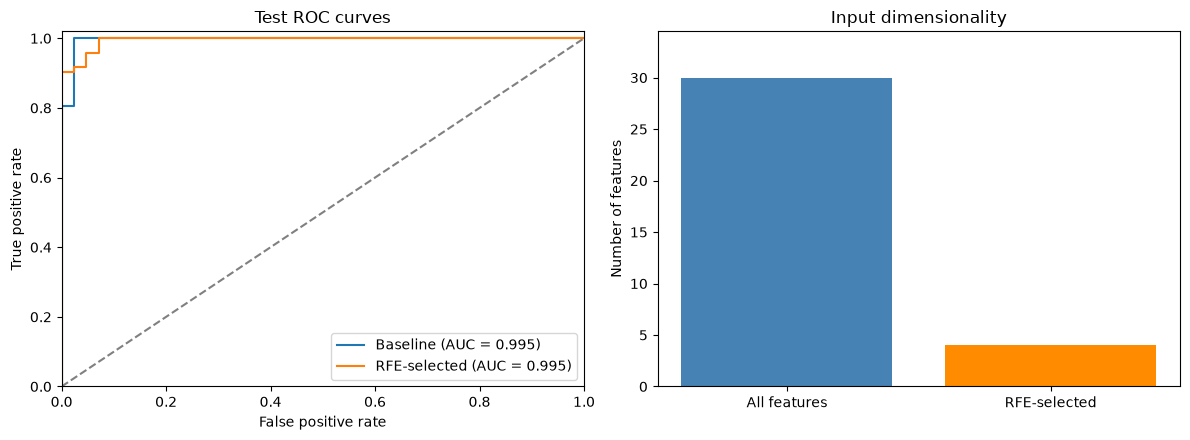

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for label, probabilities, score in [
    ("Baseline", baseline_probabilities, baseline_auc),
    ("RFE-selected", selected_probabilities, selected_auc),
]:
    false_positive_rate, true_positive_rate, _ = roc_curve(
        y_test, probabilities
    )
    axes[0].plot(
        false_positive_rate,
        true_positive_rate,
        label=f"{label} (AUC = {score:.3f})",
    )

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set(
    xlabel="False positive rate",
    ylabel="True positive rate",
    title="Test ROC curves",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
axes[0].legend(loc="lower right")

axes[1].bar(
    ["All features", "RFE-selected"],
    [original_feature_count, selected_feature_count],
    color=["steelblue", "darkorange"],
)
axes[1].set(
    ylabel="Number of features",
    title="Input dimensionality",
    ylim=(0, original_feature_count * 1.15),
)

fig.tight_layout()

## Conclusion

Use the printed comparison and plot to answer the experiment question: did this RFE run reduce the input dimensionality while keeping held-out ROC-AUC within the stated margin? The result is specific to this split, estimator, and threshold; it does not guarantee that RFE improves performance or that the same feature set is best on other data.